In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
ROOT = Path.cwd().resolve()
while not (ROOT / 'requirements.txt').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from sklearn.linear_model import Lasso
from src.evaluation import baseline_comparison as B
from src.evaluation import feature_selection as F
from src.evaluation import run_feature_selection as R
from src.features.feature_sets import FEATURE_SETS
from src.models.baselines import REGISTRY, PRIMARY

pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_rows', 120, 'display.max_colwidth', 120)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
TAB = ROOT / 'reports' / 'tables'
B.run_all()                                                  # no-op when the cache exists
df, X, y, folds = R.load()
A = pd.read_csv(B.OUT / 'expA_folds.csv'); PA = pd.read_csv(B.OUT / 'expA_predictions.csv.gz'); EB = pd.read_csv(B.OUT / 'expB_folds.csv')
META = json.loads((B.OUT / 'run_metadata.json').read_text(encoding='utf-8'))
LABEL = {n: b.label for n, b in REGISTRY.items()}
print(len(df), 'rows,', len(folds), 'folds | experiment', META['experiment_id'])

1460 rows, 15 folds | experiment baseline_v1


In [2]:
reg = pd.DataFrame([dict(model=b.label, family=b.family, config=b.config_class, scaling=b.scale or 'none',
                         primary=b.primary, parameters={k: v for k, v in b.params().items() if k not in ('copy_X', 'n_jobs', 'positive', 'verbose', 'warm_start')},
                         rationale=b.rationale) for b in REGISTRY.values()]).set_index('model')
display(reg[['family', 'config', 'scaling', 'primary']])
for n, b in REGISTRY.items():
    print(f'{b.label:20s} [{b.config_class}] {b.params()}')

,family,config,scaling,primary
model,,,,
Dummy (mean),reference,library default,none,True
OLS,linear,library default,robust,True
Ridge,linear,library default,robust,True
Lasso,linear,previously informed,robust,True
ElasticNet,linear,previously informed,robust,True
Random Forest,tree,fixed practical,none,True
Gradient Boosting,tree,library default,none,True
GBR (nb03 config),tree,previously informed,none,False
Ridge (alpha 10),linear,previously informed,robust,False


Dummy (mean)         [library default] {'constant': None, 'quantile': None, 'strategy': 'mean'}
OLS                  [library default] {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}
Ridge                [library default] {'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}
Lasso                [previously informed] {'alpha': 0.001, 'copy_X': True, 'fit_intercept': True, 'max_iter': 100000, 'positive': False, 'precompute': False, 'random_state': 42, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
ElasticNet           [previously informed] {'alpha': 0.001, 'copy_X': True, 'fit_intercept': True, 'l1_ratio': 0.5, 'max_iter': 100000, 'positive': False, 'precompute': False, 'random_state': 42, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}
Random Forest        [fixed practical] {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared

In [3]:
prim = A[A.model.isin(PRIMARY)]
T = B.comparison_table(prim, PA[PA.model.isin(PRIMARY)])
main = T[['Log-RMSE Mean', 'Log-RMSE SD', 'MAE USD', 'RMSE USD', 'MAPE %', 'R2 USD', 'Fit Time s']].copy()
main.index = [LABEL[i] for i in main.index]
main.index.name = 'Model'
display(main.round({'Log-RMSE Mean': 4, 'Log-RMSE SD': 4, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'R2 USD': 3, 'Fit Time s': 2}))
main.to_csv(TAB / 'baseline_comparison.csv')
print('Spread across the 15 folds (SD of fold scores), range, pooled score, log-scale R2:')
det = T[['Log-RMSE Min', 'Log-RMSE Max', 'Pooled Log-RMSE', 'R2 log-scale', 'MAE USD SD', 'RMSE USD SD', 'MAPE % SD', 'R2 USD SD']].copy(); det.index = [LABEL[i] for i in det.index]
display(det.round(4))
A.assign(model_label=A.model.map(LABEL)).to_csv(TAB / 'baseline_fold_level.csv', index=False)
print('fold-level results for every model and fold saved to reports/tables/baseline_fold_level.csv and artifacts/baseline_comparison/expA_folds.csv')

,Log-RMSE Mean,Log-RMSE SD,MAE USD,RMSE USD,MAPE %,R2 USD,Fit Time s
Model,,,,,,,
ElasticNet,0.1289,0.0203,15814.0,31733.0,8.88,0.825,0.52
Lasso,0.1295,0.0204,16011.0,31768.0,8.96,0.825,0.51
Gradient Boosting,0.1311,0.0154,16246.0,28248.0,9.16,0.869,1.93
Ridge,0.1322,0.0210,16104.0,32526.0,9.07,0.816,0.52
OLS,0.1341,0.0207,16362.0,32688.0,9.22,0.816,0.50
Random Forest,0.1423,0.0094,17640.0,30070.0,9.90,0.855,13.61
Dummy (mean),0.3992,0.0126,55622.0,80341.0,32.49,-0.032,0.02


Spread across the 15 folds (SD of fold scores), range, pooled score, log-scale R2:


,Log-RMSE Min,Log-RMSE Max,Pooled Log-RMSE,R2 log-scale,MAE USD SD,RMSE USD SD,MAPE % SD,R2 USD SD
ElasticNet,0.1032,0.1754,0.1304,0.8940,1843.9357,14379.3277,0.8089,0.1420
Lasso,0.1038,0.1755,0.1309,0.8931,1958.2185,14274.9580,0.8490,0.1407
Gradient Boosting,0.1146,0.1716,0.1320,0.8912,1468.6077,9638.4624,0.6541,0.0772
Ridge,0.1051,0.1802,0.1337,0.8886,1845.5495,14910.2342,0.8640,0.1516
OLS,0.1064,0.1802,0.1356,0.8854,1873.8745,14508.3358,0.8823,0.1456
Random Forest,0.1277,0.1600,0.1426,0.8726,1346.5435,6064.2485,0.5268,0.0376
Dummy (mean),0.3738,0.4248,0.3994,-0.0012,1989.0075,7770.3468,1.3120,0.0099


fold-level results for every model and fold saved to reports/tables/baseline_fold_level.csv and artifacts/baseline_comparison/expA_folds.csv


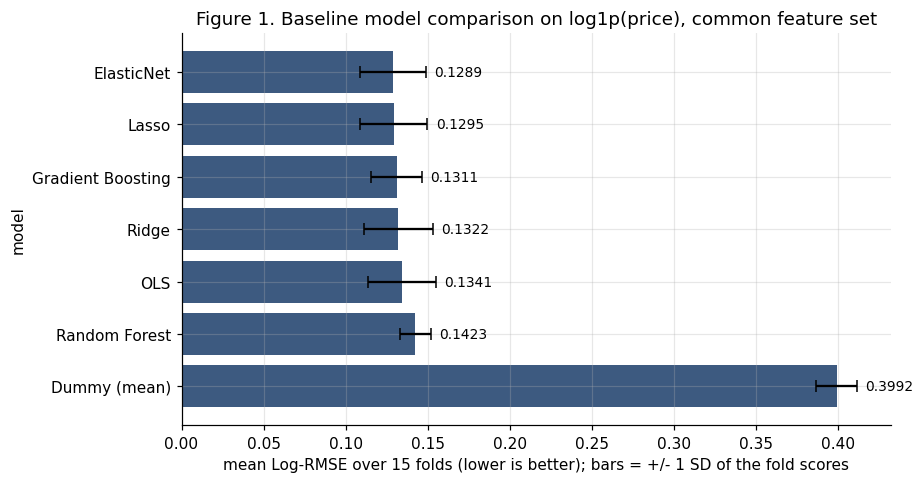

In [4]:
order = list(T.index)
lab = [LABEL[m] for m in order]
fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.barh(lab[::-1], T['Log-RMSE Mean'][::-1], xerr=T['Log-RMSE SD'][::-1], color='#3d5a80', capsize=4)
for i, m in enumerate(order[::-1]):
    ax.text(T.loc[m, 'Log-RMSE Mean'] + T.loc[m, 'Log-RMSE SD'] + .005, i, f"{T.loc[m, 'Log-RMSE Mean']:.4f}", va='center', fontsize=9)
ax.set_xlabel('mean Log-RMSE over 15 folds (lower is better); bars = +/- 1 SD of the fold scores'); ax.set_ylabel('model')
ax.set_title('Figure 1. Baseline model comparison on log1p(price), common feature set')
plt.tight_layout(); plt.savefig(FIG / 'baseline_fig1_model_comparison.png'); plt.show()

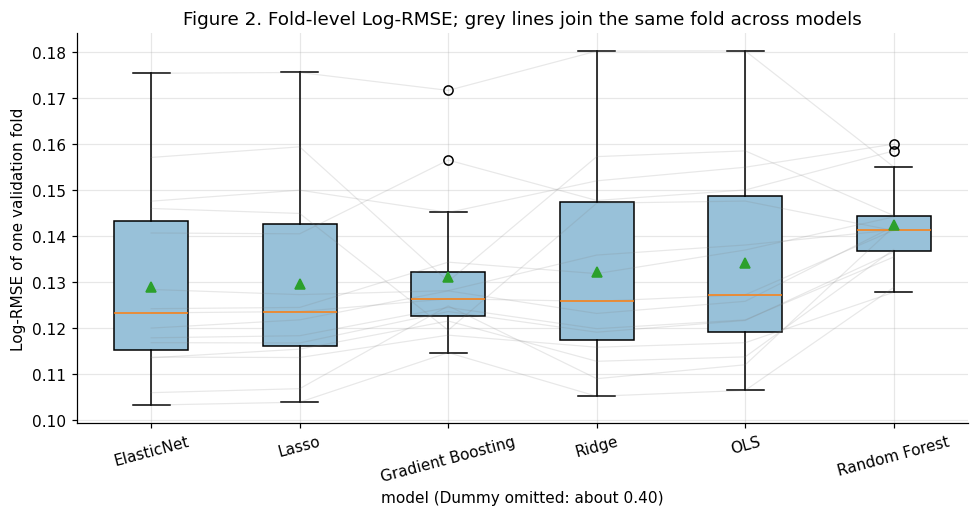

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.8))
data = [prim[prim.model == m].sort_values('fold').rmse_log.values for m in order if m != 'dummy']
bp = ax.boxplot(data, patch_artist=True, showmeans=True)
ax.set_xticks(range(1, len(data) + 1)); ax.set_xticklabels([LABEL[m] for m in order if m != 'dummy'])
for p in bp['boxes']: p.set_facecolor('#98c1d9')
for k in range(15):                                          # one line per fold: same split across models
    ax.plot(range(1, len(data) + 1), [d[k] for d in data], color='grey', alpha=.18, lw=.8)
ax.set_ylabel('Log-RMSE of one validation fold'); ax.set_xlabel('model (Dummy omitted: about 0.40)')
ax.set_title('Figure 2. Fold-level Log-RMSE; grey lines join the same fold across models')
plt.xticks(rotation=15); plt.tight_layout(); plt.savefig(FIG / 'baseline_fig2_fold_distribution.png'); plt.show()

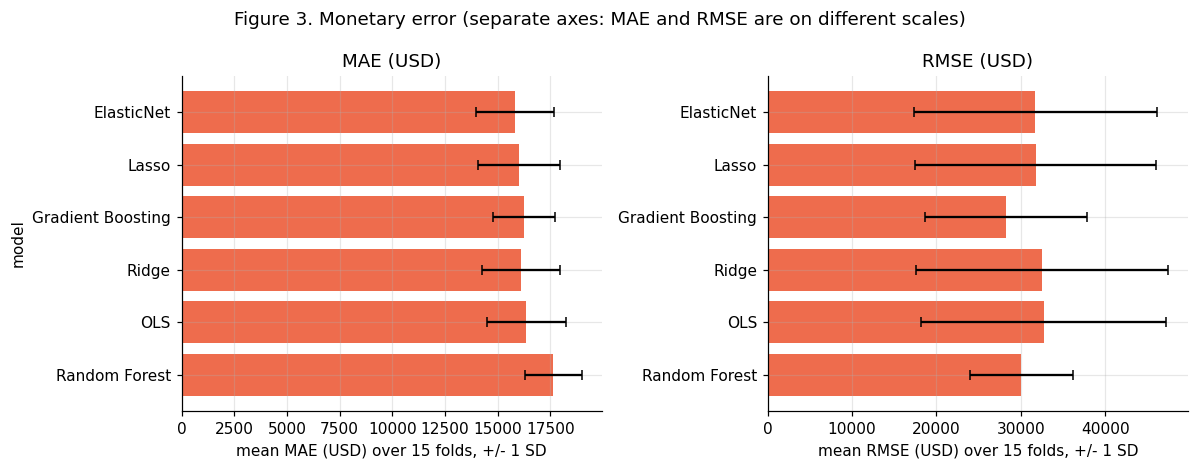

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
nd = [m for m in order if m != 'dummy']
for ax, col, ttl in zip(axes, ['MAE USD', 'RMSE USD'], ['MAE (USD)', 'RMSE (USD)']):
    ax.barh([LABEL[m] for m in nd][::-1], T.loc[nd, col][::-1], xerr=T.loc[nd, col + ' SD'][::-1], color='#ee6c4d', capsize=3)
    ax.set_xlabel(f'mean {ttl} over 15 folds, +/- 1 SD'); ax.set_title(ttl)
axes[0].set_ylabel('model')
fig.suptitle('Figure 3. Monetary error (separate axes: MAE and RMSE are on different scales)')
plt.tight_layout(); plt.savefig(FIG / 'baseline_fig3_usd_error.png'); plt.show()

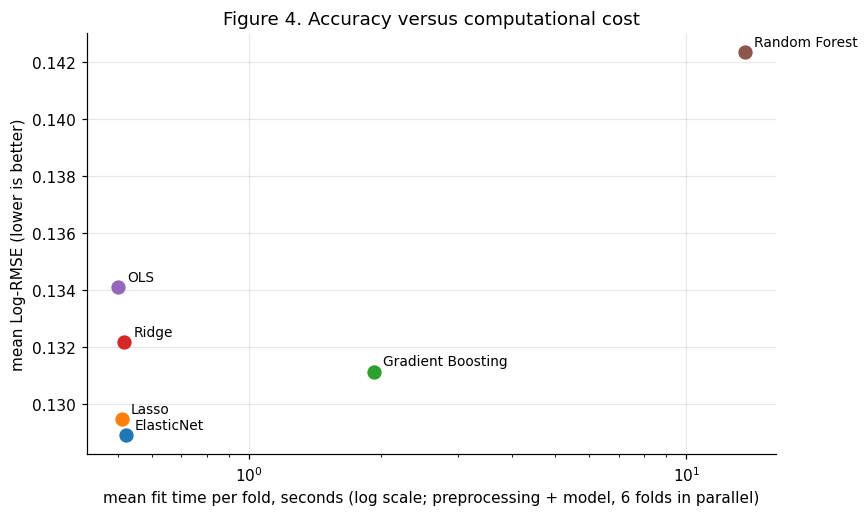

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8))
for m in nd:
    ax.scatter(T.loc[m, 'Fit Time s'], T.loc[m, 'Log-RMSE Mean'], s=70, zorder=3)
    ax.annotate(LABEL[m], (T.loc[m, 'Fit Time s'], T.loc[m, 'Log-RMSE Mean']), textcoords='offset points', xytext=(6, 4), fontsize=9)
ax.set_xscale('log'); ax.set_xlabel('mean fit time per fold, seconds (log scale; preprocessing + model, 6 folds in parallel)'); ax.set_ylabel('mean Log-RMSE (lower is better)')
ax.set_title('Figure 4. Accuracy versus computational cost')
plt.tight_layout(); plt.savefig(FIG / 'baseline_fig4_accuracy_vs_cost.png'); plt.show()

Reference: OLS (negative diff = better than OLS)


,rmse_log,diff,ci_lo,ci_hi,folds_better,repeats_better,verdict
variant,,,,,,,
ElasticNet,0.1289,-0.0052,-0.0093,-0.0011,15,3,better
Lasso,0.1295,-0.0046,-0.0093,-0.0000,13,3,better
Gradient Boosting,0.1311,-0.0030,-0.0177,0.0118,7,2,tie
Ridge,0.1322,-0.0019,-0.0035,-0.0004,15,3,better
Random Forest,0.1423,0.0083,-0.0093,0.0258,3,0,tie
Dummy (mean),0.3992,0.2651,0.2450,0.2852,0,0,worse


Reference: Gradient Boosting (negative diff = better than Gradient Boosting)


,rmse_log,diff,ci_lo,ci_hi,folds_better,repeats_better,verdict
variant,,,,,,,
ElasticNet,0.1289,-0.0022,-0.0182,0.0138,10,2,tie
Lasso,0.1295,-0.0017,-0.0178,0.0144,11,2,tie
Ridge,0.1322,0.0010,-0.0142,0.0163,10,1,tie
OLS,0.1341,0.0030,-0.0118,0.0177,8,1,tie
Random Forest,0.1423,0.0112,0.0006,0.0219,1,0,worse


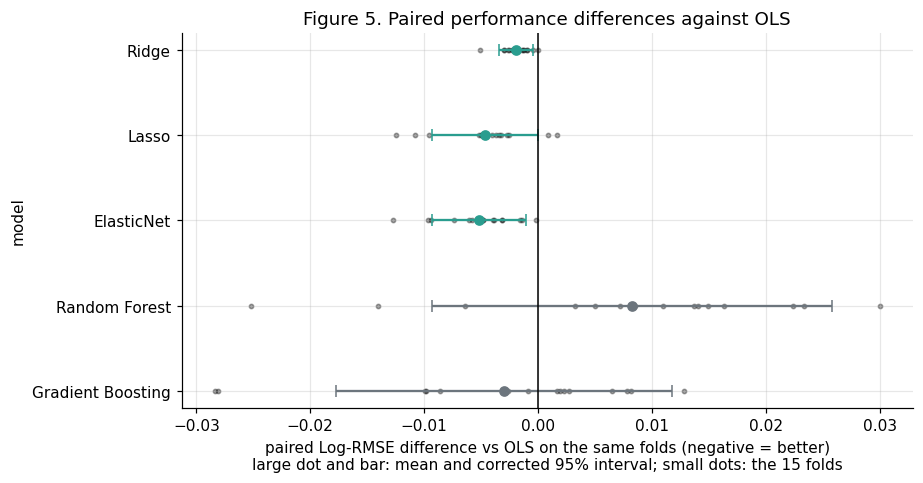

In [8]:
mets = {m: prim[prim.model == m].sort_values('fold').reset_index(drop=True) for m in PRIMARY}
vs_ols = F.paired_vs_reference(mets, 'ols')
cols = ['rmse_log', 'diff', 'ci_lo', 'ci_hi', 'folds_better', 'repeats_better', 'verdict']
print('Reference: OLS (negative diff = better than OLS)'); display(vs_ols.loc[[m for m in order if m != 'ols'], cols].rename(index=LABEL).round(4))
gbr_set = {m: mets[m] for m in ['gbr', 'elasticnet', 'lasso', 'ridge', 'rf', 'ols']}
vs_gbr = F.paired_vs_reference(gbr_set, 'gbr')
print('Reference: Gradient Boosting (negative diff = better than Gradient Boosting)'); display(vs_gbr.loc[['elasticnet', 'lasso', 'ridge', 'ols', 'rf'], cols].rename(index=LABEL).round(4))
fig, ax = plt.subplots(figsize=(8.5, 4.5))
rows = [m for m in ['ridge', 'lasso', 'elasticnet', 'rf', 'gbr']]
for k, m in enumerate(rows):
    r = vs_ols.loc[m]
    ax.errorbar(r['diff'], k, xerr=[[r['diff'] - r.ci_lo], [r.ci_hi - r['diff']]], fmt='o', capsize=4,
                color={'better': '#2a9d8f', 'tie': '#6c757d', 'worse': '#d1495b'}[r.verdict])
    ax.scatter(mets[m].rmse_log.values - mets['ols'].rmse_log.values, [k] * 15, color='k', s=8, alpha=.35, zorder=1)
ax.axvline(0, color='k', lw=1); ax.set_yticks(range(len(rows))); ax.set_yticklabels([LABEL[m] for m in rows]); ax.invert_yaxis()
ax.set_xlabel('paired Log-RMSE difference vs OLS on the same folds (negative = better)\nlarge dot and bar: mean and corrected 95% interval; small dots: the 15 folds')
ax.set_ylabel('model'); ax.set_title('Figure 5. Paired performance differences against OLS')
plt.tight_layout(); plt.savefig(FIG / 'baseline_fig5_paired_vs_ols.png'); plt.show()

In [9]:
tr, va = folds[0]
prep = FEATURE_SETS['reduced'].build('baseline', scale='robust').fit(X.iloc[tr], np.log1p(y[tr]))
Z = prep.transform(X.iloc[tr])
rk = np.linalg.matrix_rank(Z.values)
print(f'OLS design matrix (fold 1 training, reduced set): {Z.shape[0]} rows x {Z.shape[1]} columns, rank {rk}, condition number {np.linalg.cond(Z.values):.2e}')
for a in (1.0, 1e-3):
    l = Lasso(alpha=a, max_iter=100000).fit(Z, np.log1p(y[tr]))
    print(f'Lasso alpha={a}: {int((l.coef_ != 0).sum())} non-zero coefficients (diagnostic on one training fold, not a selection step)')
conv = A[A.model.isin(['lasso', 'elasticnet'])].groupby('model').n_iter.agg(['min', 'max']).assign(max_iter=100000)
conv['all folds converged (n_iter < max_iter)'] = conv['max'] < conv.max_iter
display(conv)
print('non-finite predictions anywhere:', int((~A.all_finite).sum()), '| convergence warnings: none (every solver stopped well before max_iter)')

OLS design matrix (fold 1 training, reduced set): 1168 rows x 166 columns, rank 147, condition number 6.40e+17
Lasso alpha=1.0: 0 non-zero coefficients (diagnostic on one training fold, not a selection step)
Lasso alpha=0.001: 59 non-zero coefficients (diagnostic on one training fold, not a selection step)


,min,max,max_iter,all folds converged (n_iter < max_iter)
model,,,,
elasticnet,79.0,145.0,100000,True
lasso,76.0,90.0,100000,True


non-finite predictions anywhere: 0 | convergence warnings: none (every solver stopped well before max_iter)


In [10]:
sup = A[A.model.isin(['gbr', 'gbr_nb03', 'ridge', 'ridge_a10'])]
St = B.comparison_table(sup, PA[PA.model.isin(['gbr', 'gbr_nb03', 'ridge', 'ridge_a10'])])[['Log-RMSE Mean', 'Log-RMSE SD', 'MAE USD', 'RMSE USD', 'MAPE %', 'R2 USD', 'Fit Time s']]
St['configuration class'] = [REGISTRY[m].config_class for m in St.index]; St.index = [LABEL[m] for m in St.index]
display(St.round({'Log-RMSE Mean': 4, 'Log-RMSE SD': 4, 'MAE USD': 0, 'RMSE USD': 0, 'MAPE %': 2, 'R2 USD': 3, 'Fit Time s': 2}))
d = F.paired_vs_reference({'gbr': mets['gbr'], 'gbr_nb03': A[A.model == 'gbr_nb03'].sort_values('fold').reset_index(drop=True)}, 'gbr')
display(d.loc[['gbr_nb03'], cols].rename(index=LABEL).round(4))

,Log-RMSE Mean,Log-RMSE SD,MAE USD,RMSE USD,MAPE %,R2 USD,Fit Time s,configuration class
GBR (nb03 config),0.1262,0.0124,15565.0,26987.0,8.76,0.882,4.28,previously informed
Ridge (alpha 10),0.1309,0.0212,15910.0,32846.0,8.96,0.809,0.52,previously informed
Gradient Boosting,0.1311,0.0154,16246.0,28248.0,9.16,0.869,1.93,library default
Ridge,0.1322,0.0210,16104.0,32526.0,9.07,0.816,0.52,library default


,rmse_log,diff,ci_lo,ci_hi,folds_better,repeats_better,verdict
variant,,,,,,,
GBR (nb03 config),0.1262,-0.005,-0.0119,0.002,13,3,tie


In [11]:
rows = []
for m in ['ols', 'ridge', 'lasso', 'elasticnet', 'rf', 'gbr']:
    mm = {s: EB[(EB.model == m) & (EB.feature_set == s)].sort_values('fold').reset_index(drop=True) for s in ['reduced', 'full', 'domain_informed']}
    t = F.paired_vs_reference(mm, 'reduced'); t.insert(0, 'model', LABEL[m]); rows.append(t.reset_index().rename(columns={'variant': 'feature_set'}))
EBT = pd.concat(rows, ignore_index=True)
display(EBT[['model', 'feature_set', 'n_features', 'rmse_log', 'rmse_sd', 'mae_usd', 'mape_pct', 'diff', 'ci_lo', 'ci_hi', 'verdict']].round(4).set_index(['model', 'feature_set']))

n_features  rmse_log  rmse_sd     mae_usd  mape_pct    diff   ci_lo   ci_hi    verdict
model             feature_set                                                                                            
OLS               reduced            166.8667    0.1341   0.0207  16362.2119    9.2188  0.0000  0.0000  0.0000  reference
                  full               190.3333    0.1448   0.0301  16911.8237    9.5532  0.0107 -0.0123  0.0337        tie
                  domain_informed    174.8667    0.1355   0.0238  16454.9521    9.3178  0.0015 -0.0036  0.0065        tie
Ridge             reduced            166.8667    0.1322   0.0210  16104.4851    9.0677  0.0000  0.0000  0.0000  reference
                  full               190.3333    0.1369   0.0271  16443.3220    9.2974  0.0047 -0.0053  0.0148        tie
                  domain_informed    174.8667    0.1336   0.0240  16212.6122    9.1722  0.0015 -0.0033  0.0063        tie
Lasso             reduced            166.8667    0.1295   0.0204  16010.5859    8.9645  0.0000  0.0000  0.0000  reference
                  full               190.3333    0.1297   0.0258  15754.6736    8.8714  0.0002 -0.0089  0.0094        tie
                  domain_informed    174.8667    0.1306   0.0240  16043.2514    9.0046  0.0012 -0.0043  0.0066        tie
ElasticNet        reduced            166.8667    0.1289   0.0203  15813.9656    8.8758  0.0000  0.0000  0.0000  reference
                  full               190.3333    0.1297   0.0258  15642.6126    8.8316  0.0008 -0.0079  0.0096        tie
                  domain_informed    174.8667    0.1300   0.0238  15852.5093    8.9264  0.0011 -0.0040  0.0063        tie
Random Forest     reduced            166.8667    0.1423   0.0094  17640.0594    9.9002  0.0000  0.0000  0.0000  reference
                  full               190.3333    0.1411   0.0096  17256.5914    9.8458 -0.0012 -0.0057  0.0032        tie
                  domain_informed    174.8667    0.1415   0.0099  17483.7432    9.8579 -0.0009 -0.0031  0.0014        tie
Gradient Boosting reduced            166.8667    0.1311   0.0154  16245.5685    9.1563  0.0000  0.0000  0.0000  reference
                  full               190.3333    0.1293   0.0141  15613.2031    8.9114 -0.0018 -0.0097  0.0061        tie
                  domain_informed    174.8667    0.1310   0.0146  16063.0829    9.0951 -0.0002 -0.0041  0.0038        tie

In [12]:
checks = []
def add(name, ok, detail=''): checks.append((name, 'PASS' if ok else 'FAIL', detail))
add('all seven primary models executed on 15 folds', set(PRIMARY) <= set(A.model) and (A[A.model.isin(PRIMARY)].groupby('model').fold.nunique() == 15).all())
add('identical train/validation rows for every model', PA.groupby('model').apply(lambda d: tuple(sorted(zip(d.fold, d.row)))).nunique() == 1)
add('fold splits match the shared get_folds output', META['cv']['fold_hash'] == __import__('hashlib').sha256(np.concatenate([np.r_[a, b] for a, b in folds]).astype(np.int64).tobytes()).hexdigest())
add('all predictions finite', bool(A.all_finite.all()) and bool(np.isfinite(PA.pred_log).all()))
add('actual prices strictly positive', bool((y > 0).all()))
# independent recomputation of every fold metric from the stored out-of-fold predictions
ok = True
for (m, k), d in PA.groupby(['model', 'fold']):
    pred = np.expm1(d.pred_log.values); yt = d.y.values
    row = A[(A.model == m) & (A.fold == k)].iloc[0]
    ok &= np.isclose(np.sqrt(np.mean((d.pred_log.values - np.log1p(yt)) ** 2)), row.rmse_log) and np.isclose(np.mean(np.abs(pred - yt)), row.mae) \
          and np.isclose(np.sqrt(np.mean((pred - yt) ** 2)), row.rmse_usd) and np.isclose(100 * np.mean(np.abs(pred - yt) / yt), row.mape) \
          and np.isclose(1 - np.sum((yt - pred) ** 2) / np.sum((yt - yt.mean()) ** 2), row.r2_usd)
add('all five metrics recomputed from stored predictions match the stored fold results', bool(ok))
add('USD back-transform: expm1(log1p(y)) recovers y', bool(np.allclose(np.expm1(np.log1p(y)), y)))
add('each row validated exactly 3 times per model (3 repeats)', bool((PA[PA.model == 'ols'].groupby('row').size() == 3).all()))
add('no tuning estimator or search in the registry', all(not any(s in type(b.factory()).__name__ for s in ('CV', 'Search')) for b in REGISTRY.values()))
add('Dummy is included and uses no preprocessing', 'dummy' in set(A.model) and REGISTRY['dummy'].scale is None)
add('sale-context variables excluded from every feature set', all(c not in FEATURE_SETS['reduced'].build().fit_transform(X.iloc[:300]).columns for c in ['SaleType', 'SaleCondition', 'MoSold', 'YrSold']))
add('test.csv not used', True, 'only train.csv is read (load_raw default); no code path reads test data')
display(pd.DataFrame(checks, columns=['check', 'result', 'detail']).set_index('check'))
import unittest
res = unittest.TextTestRunner(stream=open('NUL' if sys.platform == 'win32' else '/dev/null', 'w'), verbosity=0).run(unittest.defaultTestLoader.loadTestsFromName('tests.test_baselines'))
print(f'tests.test_baselines: ran {res.testsRun}, failures {len(res.failures)}, errors {len(res.errors)}, skipped {len(res.skipped)}')

,result,detail
check,,
all seven primary models executed on 15 folds,PASS,
identical train/validation rows for every model,PASS,
fold splits match the shared get_folds output,PASS,
all predictions finite,PASS,
actual prices strictly positive,PASS,
all five metrics recomputed from stored predictions match the stored fold results,PASS,
USD back-transform: expm1(log1p(y)) recovers y,PASS,
each row validated exactly 3 times per model (3 repeats),PASS,
no tuning estimator or search in the registry,PASS,


tests.test_baselines: ran 9, failures 0, errors 0, skipped 0


In [13]:
print(json.dumps({k: META[k] for k in ['experiment_id', 'timestamp', 'runtime_seconds', 'dataset_sha256', 'n_rows', 'cv', 'target', 'versions', 'machine']}, indent=2))

{
  "experiment_id": "baseline_v1",
  "timestamp": "2026-10-10T15:49:40",
  "runtime_seconds": 200.7,
  "dataset_sha256": "ed142e0a97bd49fc3b46c930209c55750fc4e806f5430c7d7409cb4cf25149cb",
  "n_rows": 1460,
  "cv": {
    "splitter": "get_folds: RepeatedStratifiedKFold on 5 price bands",
    "n_splits": 5,
    "n_repeats": 3,
    "seed": 42,
    "n_folds": 15,
    "fold_hash": "ef77356db28a0ed9150a1aae847c3d16758363c6e1b0fd5074bc2ea2f95f5134"
  },
  "target": "log1p(SalePrice); USD predictions = expm1 (median, no smearing correction)",
  "versions": {
    "python": "3.14.2",
    "sklearn": "1.9.1",
    "numpy": "2.5.3",
    "pandas": "3.0.6"
  },
  "machine": "Intel64 Family 6 Model 186 Stepping 2, GenuineIntel"
}
